In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.DataFrame([[153,63], [174,81], [136,56],
                   [186,91], [128,47], [136,57],
                   [179,76], [163,72],[131,48]])

df.columns = ["x", "y"]

In [3]:
df.corr()

,x,y
x,1.000000,0.976058
y,0.976058,1.000000


In [4]:
x_train = df['x'].values[:,np.newaxis]
y_train = df['y'].values

x_train

array([[153],
       [174],
       [136],
       [186],
       [128],
       [136],
       [179],
       [163],
       [131]])

In [5]:
y_train

array([63, 81, 56, 91, 47, 57, 76, 72, 48])

In [6]:
lm = LinearRegression()
lm.fit(x_train, y_train)

LinearRegression()

In [7]:
#membuat prediksi

x_test = [[170], [160], [180], [171], [150]]
p = lm.predict(x_test)
p 

array([76.3373494 , 69.66817269, 83.0065261 , 77.00426707, 62.99899598])

In [8]:
# koefisien regresi & intersep

print("Coefficient :", lm.coef_)
print("Intercept :", lm.intercept_)

Coefficient : [0.66691767]
Intercept : -37.0386546184739


Text(0, 0.5, 'Nilai y')

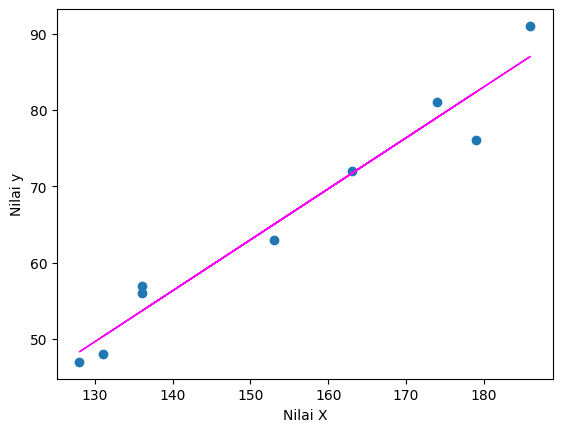

In [9]:
#visualisasikam model

pb = lm.predict(x_train)
dfc = pd.DataFrame({"x": df["x"], "y" : pb})
plt.scatter(df['x'], df['y'])
plt.plot(dfc['x'], dfc['y'], color="magenta", linewidth=1)
plt.xlabel('Nilai X')
plt.ylabel('Nilai y')

In [10]:
df = pd.read_csv("botak.csv")
df

,umur,jenis_kelamin,pekerjaan,provinsi,gaji,is_menikah,is_keturunan,berat,tinggi,sampo,is_merokok,pendidikan,botak_prob
0,42.0,Laki-laki,PNS,Padang,7.864005e+06,0,0.0,61.928685,152.174164,Deadbuoy,1,S1,0.487655
1,33.0,Laki-laki,Pegawai swasta,Palangkaraya,6.492662e+06,0,0.0,49.374507,152.822969,Moonsilk,1,SMA,0.297270
2,59.0,Laki-laki,Freelance,Serang,8.086303e+06,1,0.0,59.072807,159.911047,Merpati,1,S1,0.467848
3,38.0,Laki-laki,Pegawai swasta,Gorontalo,1.147321e+07,0,1.0,68.338014,162.558997,Moonsilk,0,S1,0.616418
4,33.0,Perempuan,Freelance,Tanjungselor,1.475942e+07,0,0.0,53.769996,154.579510,Pantone,1,S2,0.115439
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7986,31.0,Laki-laki,Pegawai swasta,Padang,2.911963e+07,0,0.0,83.272785,176.020857,Merpati,0,SMA,0.241525
7987,40.0,Perempuan,Pegawai swasta,Banjarmasin,8.955173e+06,0,0.0,61.634474,161.780773,Deadbuoy,0,S1,0.140971
7988,43.0,Perempuan,PNS,Mataram,4.022652e+06,0,0.0,50.525031,152.461656,Shoulder & Head,1,S1,0.364456
7989,29.0,Laki-laki,Pegawai swasta,Serang,5.801753e+06,0,0.0,47.175270,152.749709,NaN,1,SMA,0.248910


In [11]:
df.info

<bound method DataFrame.info of       umur jenis_kelamin       pekerjaan      provinsi          gaji  \
0     42.0     Laki-laki             PNS        Padang  7.864005e+06   
1     33.0     Laki-laki  Pegawai swasta  Palangkaraya  6.492662e+06   
2     59.0     Laki-laki       Freelance        Serang  8.086303e+06   
3     38.0     Laki-laki  Pegawai swasta     Gorontalo  1.147321e+07   
4     33.0     Perempuan       Freelance  Tanjungselor  1.475942e+07   
...    ...           ...             ...           ...           ...   
7986  31.0     Laki-laki  Pegawai swasta        Padang  2.911963e+07   
7987  40.0     Perempuan  Pegawai swasta   Banjarmasin  8.955173e+06   
7988  43.0     Perempuan             PNS       Mataram  4.022652e+06   
7989  29.0     Laki-laki  Pegawai swasta        Serang  5.801753e+06   
7990  55.0     Laki-laki  Pegawai swasta        Padang  8.518947e+06   

      is_menikah  is_keturunan      berat      tinggi            sampo  \
0              0           0.

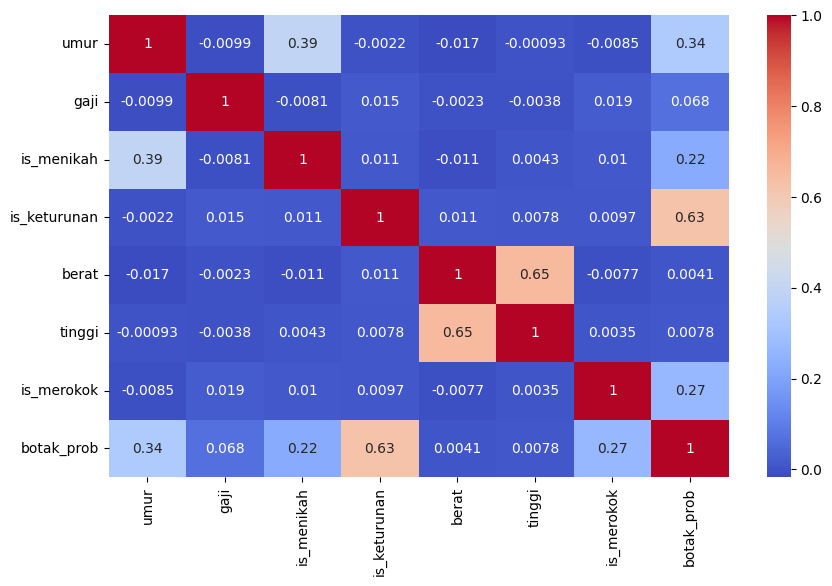

In [12]:
import seaborn as sns
num_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [13]:
db_clean = df.dropna(subset=["umur", "gaji", "tinggi", "berat", "botak_prob"])

x = db_clean[["umur", "gaji", "tinggi", "berat"]]
y = db_clean["botak_prob"]

In [14]:
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size=0.2, random_state=0)

In [15]:
model = LinearRegression()

model.fit(x_train, y_train)

LinearRegression()

In [16]:
y_pred = model.predict(x_test)

In [19]:
#evaluasi

from sklearn.metrics import mean_squared_error, r2_score

print("Coefficient :", lm.coef_)
print("Intercept :", lm.intercept_)
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score : ", r2_score(y_test, y_pred))

Coefficient : [0.66691767]
Intercept : -37.0386546184739
MSE : 0.03177222988707976
R2 Score :  0.10923976549414827


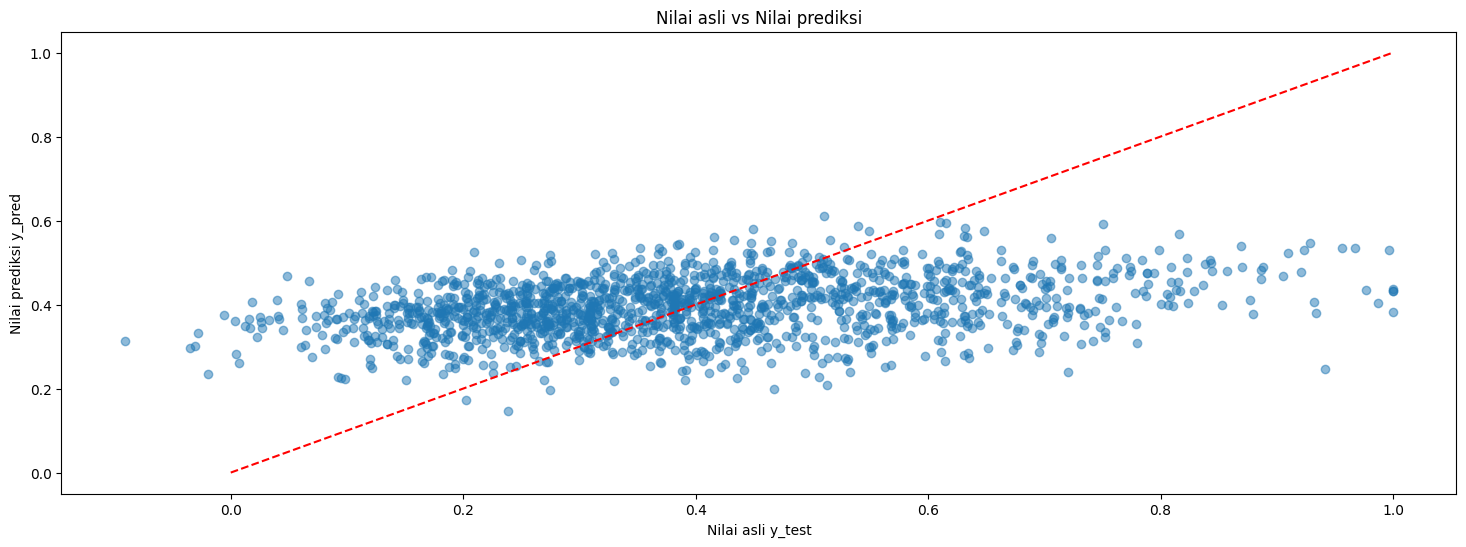

In [24]:
plt.figure(figsize=(18,6))
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("Nilai asli y_test")
plt.ylabel("Nilai prediksi y_pred")
plt.title("Nilai asli vs Nilai prediksi")
plt.plot([0,1],[0,1],'r--')
plt.show()